<a href="https://colab.research.google.com/github/serraozkasap/ml-ai4i-predictive-maintenance/blob/main/ai4i_predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on CRISP-DM I'll follow these steps:

1. Business Understanding,
2. Data Understanding,
3. Data Preparation,
4. Modeling,
5. Evaluation,
6. Conclusions

## 1. Business Understanding

**Problem:** Unplanned machine stops break the production flow, increase costs and reduce efficiency. When a machine fails during production, the parts it is making often become scrap and the repair has to be done at the worst possible moment.

**My goal of this project:** I want to predict, from the sensor readings of a milling machine, whether it is going to fail (`Machine failure = 1`) and understand which conditions lead to a failure. If a failure can be predicted before it happens, maintenance can be planned, the machine can be stopped at a convenient time and scrap and maintenance costs go down.

**Which error is more expensive, I will focus for my interpration:**

- *Missed failure (false negative):* the model says "OK" but the machine fails. This causes an unplanned stop, scrap and possibly a damaged tool. **This is the expensive error. I'm planning to focus this one.**
- *False alarm (false positive):* the model says "failure" but the machine is fine. This causes one unnecessary inspection, which is a short and planned stop.

**Which metric will I focus on?**

- Only 3.39% of the records are failures (see Data Understanding session). A model that always predicts "no failure" would reach 96.61% accuracy and still miss every failure, so I understand that **accuracy is not a useful metric here**.
- My main metric is **recall on the failure class**: the share of real failures the model catches.
- A model that raises an alarm on every record has recall = 1 but is useless, so I also track **precision** (how many alarms are real failures).
- To compare models and choose the decision threshold I use the **F2-score**, which combines precision and recall but gives recall more weight, because a missed failure costs more than a false alarm.
- For every model I will report the confusion matrix, precision, recall, F2-score and the precision-recall curve (PR-AUC).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/serraozkasap/ml-ai4i-predictive-maintenance/refs/heads/main/predictive-maintenance-dataset-ai4i-2020.csv") #I just want to without uploading any file by hand (Colab deletes uploaded files when the session ends).
print(df.shape) #how many row and column we have

(10000, 14)


   # 2. Data Understanding

In [4]:
df.head() #I want to see couple lines of dataset to understand how it looks like
#each row is one machine record with an ID (UDI, Product ID)-we can eliminate these ones on feature engineering part-, the product quality type (L/M/H),
#five sensor readings, the target "Machine failure" and five failure-mode flags (TWF, HDF, PWF, OSF, RNF)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.info() #trying to see whole dataset data type and is there any null (it's important for accurate analysis)
#"Type" must be encoded as numbers before modeling
#"Product ID" is only an identifier

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [6]:
print(df.isna().sum()) #to count the missing values per column. Missing values would have to be removed or imputed in that case we don't need imputations

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [7]:
print("Duplicated rows:", df.duplicated().sum()) #duplicated rows lower data quality. If the same row ended up in both the training set and the
#test set, the model would be tested on data it has already seen and the test score would look.
#in that case we don't need to remove, the train/test split later will not have overlapping records

Duplicated rows: 0


In [8]:
df.describe() #I want to make plausibility check, see is the statistical metrics on our dataset like mean, std, min, quartiles and max but only for numerical columns
#it would help me to understand the range of each sensor and whether some features need scaling

#rotational speed is around 1538.78 rpm
#torque around 39.99 Nm,
#temperatures around 310 K

#all values are physically plausible so no negative values, temperatures in Kelvin around 295-314 K (make sense)

#tool wear between 0 and 253 minutes. It shows me that some of the tools didnot used before and some of them working for 253 min

#the mean of "Machine failure" is 0.0339, so only 3.39% of the records are failures. I'll mentioned it on Business Dev. part!!

#UDI only counts the rows from 1 to 10,000, so it carries no information. I'LL ELIMINATE IT ON MY DATA PREPARATION PART, NO NEED TO USE.

#distance-based and gradient-based models (KNN, logistic regression, neural networks) need scaling,
#otherwise rotational speed would dominate the other features
#tree-based models do not need scaling

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [9]:
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True) * 100) #to see how the target classes are distributed (counts and percentages)

#9,661 records without failure (96.61%) and only 339 with failure (3.39%). I'LL MENTIONED THIS ON BUSINESS DEV PART!!
#The minority class is about 28 times smaller, which shows dataset imbalanced

#so accuracy would be misleading, I'll evaluate with recall, precision and F2
#I'll also use a stratified train/test split, so both sets keep the same share of failures

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [10]:
print(df["Type"].value_counts(normalize=True) * 100) #to see the distribution of the product quality types (L = low, M = medium, H = high).

#"Type" has a natural order (L < M < H), so in Data Preparation I'LL USE ORDINAL ENCODING INSTEAD OF ONE-HOT ENCODING!!

Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


In [11]:
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"] #I keep the five sensor columns in one list, so I can reuse it for plots and for scaling later.

print("Process temp > air temp in all rows:",(df["Process temperature [K]"] > df["Air temperature [K]"]).all()) #in there I checked process heats up the machine, so the process temperature should always
#be higher than the air temperature. A row where this is false would be a measurement error. it looks like there are no implausible temperature records.

Process temp > air temp in all rows: True


In [12]:
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"] #consistency check between the target and the five failure modes because according to the dataset description, "Machine failure" is 1 when at least one failure mode is 1.

mode_count = df[modes].sum(axis=1) #for each row: how many failure modes are active (0, 1, 2, ...)

#Case 1: a failure is recorded, but no failure mode explains it (false negative)
failure_without_mode = (df["Machine failure"] == 1) & (mode_count == 0)

# Case 2: a failure mode is recorded, but no failure (false positive)
mode_without_failure = (df["Machine failure"] == 0) & (mode_count > 0)

print("Failure but no mode:", failure_without_mode.sum()) #9 failures without a mode
print("Mode but no failure:", mode_without_failure.sum()) #18 modes without failure

#so 27 rows (0.27%) are inconsistent.these are label-quality issues. I'LL DECIDE HOW TO HANDLE THEM IN DATA PREPARATION!!!!

Failure but no mode: 9
Mode but no failure: 18


In [13]:
print(df.loc[mode_without_failure, modes].sum()) #to find out which failure mode appears in the 18 rows where no failure was recorded.

#18 are RNF (random failure). RNF is the only mode that is not caused by the process
#it is a random event, so it cannot be predicted from the sensor readings anyway

#I think this information only supports keeping "Machine failure" as the target and treating these rows as label noise.

TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64


#3. Data Understanding with Visualization

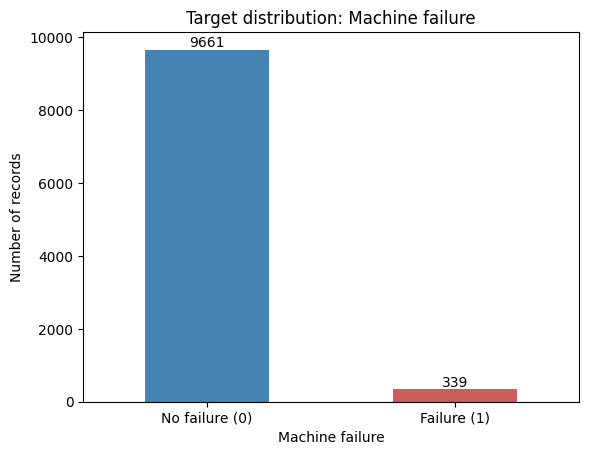

In [14]:
#I want to show the class imbalance visually (it is easier to see than a percentage, and I can use this figure in the report)
ax = df["Machine failure"].value_counts().plot(kind="bar", color=["steelblue", "indianred"])
ax.set_xticklabels(["No failure (0)", "Failure (1)"], rotation=0)
ax.set_ylabel("Number of records")
ax.set_title("Target distribution: Machine failure")
for p in ax.patches:  # write the count on top of each bar
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

#the "Failure" bar is tiny compared with "No failure" (339 vs 9,661)
#it confirms that accuracy is not a good metric and that I need a stratified split!!!

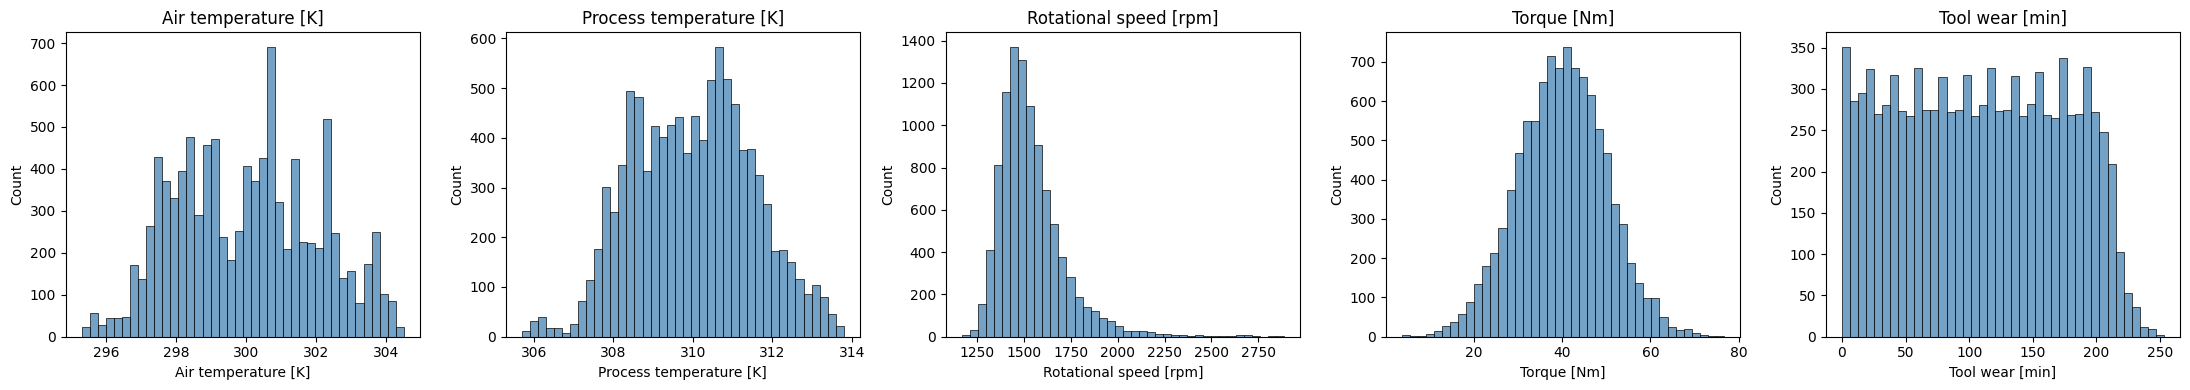

In [15]:
#I want to see the shape of each sensor's distribution (symmetric or skewed, one peak or more)
#because skewed features can need a transformation, and the shape helps me choose the scaling method
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

#skewness gives one number for the asymmetry (0 = symmetric, > 1 = strongly right-skewed)

In [16]:
print(df[num_cols].skew().round(2))

#I'll put these informations to the report:
#- torque and process temperature look roughly bell-shaped and symmetric (skewness close to 0).
#- air temperature is also symmetric (skewness 0.11) but irregular, with several peaks instead of one smooth bell.
#- Tool wear is almost flat between 0 and ~200 minutes (every tool age is equally common), and very few records are above ~220 minutes.
#- Rotational speed is right-skewed (skewness 1.99): most records are around 1,400-1,600 rpm, with a long tail up to ~2,900 rpm.

#for models that are sensitive to scale I will use standardization!!!
#Because rotational speed is skewed, I can also test a log transformation in Data Preparation and compare. Tree-based models are not affected by skewness.

Air temperature [K]        0.11
Process temperature [K]    0.02
Rotational speed [rpm]     1.99
Torque [Nm]               -0.01
Tool wear [min]            0.03
dtype: float64


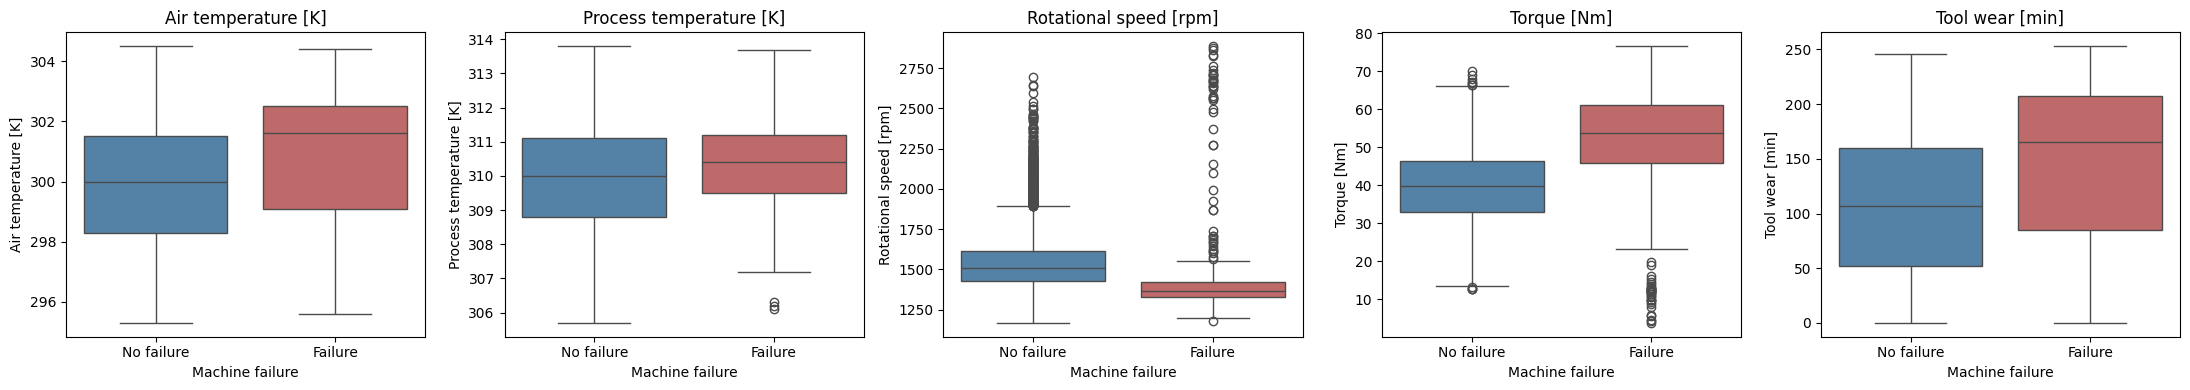

                 Air temperature [K]  Process temperature [K]  \
Machine failure                                                 
0                              300.0                    310.0   
1                              301.6                    310.4   

                 Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Machine failure                                                        
0                                1507.0         39.9            107.0  
1                                1365.0         53.7            165.0  


In [17]:
#compare each sensor between normal records (0) and failures (1)
#if the two boxes are clearly different, the sensor is useful to predict a failure.
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=ax, hue="Machine failure",
                palette=["steelblue", "indianred"], legend=False)
    ax.set_title(col)
    ax.set_xticks([0, 1], ["No failure", "Failure"])
plt.tight_layout()
plt.show()

#medians behind the boxes, so I can WRITE EXACT NUMBERS TO THE REPORT!!
print(df.groupby("Machine failure")[num_cols].median().round(1))

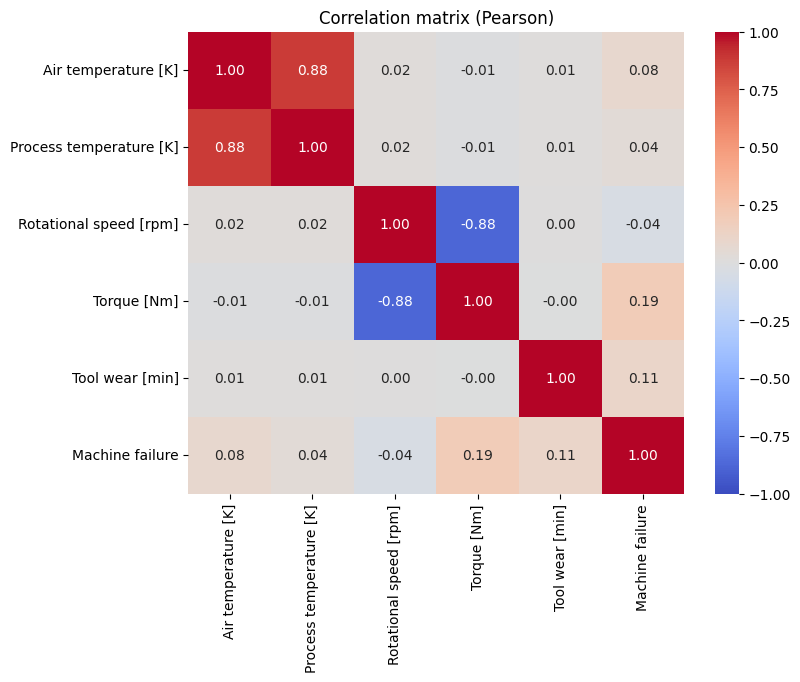

In [18]:
#I want to see which features move together. Strongly correlated features carry almost the same
#redundancy and correlation with the target shows which features matter
corr = df[num_cols + ["Machine failure"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (Pearson)")
plt.show()

#I CAN USE THIS GRAPH ON PRESENTATION TO EXPLAIN CORRELATIONS!

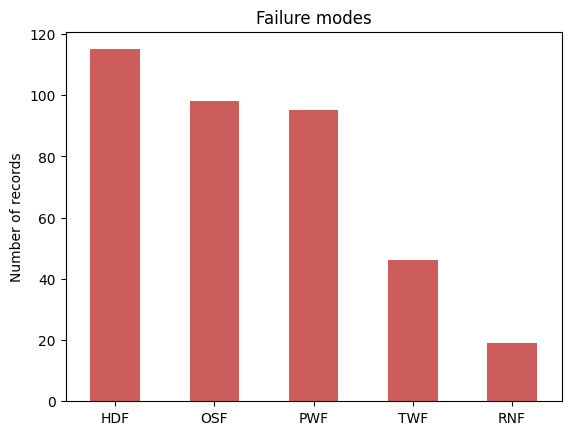

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64
Records with more than one failure mode: 24


In [19]:
#see which failure types are frequent. The model predicts "Machine failure" in general, but knowing which causes are common helps me explain the results.
modes_count = df[modes].sum().sort_values(ascending=False)
ax = modes_count.plot(kind="bar", color="indianred")
ax.set_ylabel("Number of records")
ax.set_title("Failure modes")
plt.xticks(rotation=0)
plt.show()
print(modes_count)

#one record can have more than one failure mode at the same time
print("Records with more than one failure mode:", (df[modes].sum(axis=1) > 1).sum())

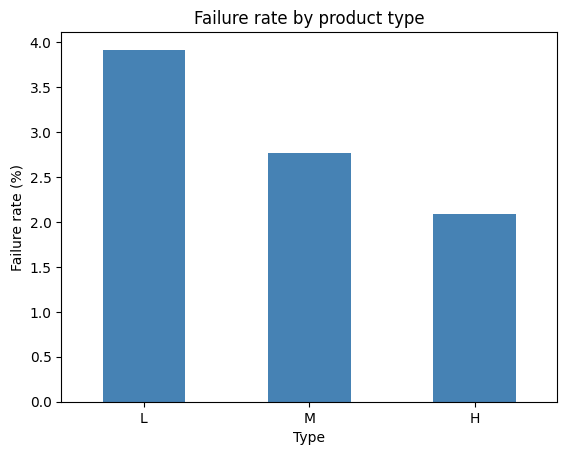

Type
L    3.92
M    2.77
H    2.09
Name: Machine failure, dtype: float64


In [20]:
#I want to check whether the product quality type (L/M/H) changes the failure rate
#mean of a 0/1 column is the share of 1s, so this gives the failure rate per type.
rate_by_type = df.groupby("Type")["Machine failure"].mean().loc[["L", "M", "H"]] * 100
ax = rate_by_type.plot(kind="bar", color="steelblue")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Failure rate by product type")
plt.xticks(rotation=0)
plt.show()
print(rate_by_type.round(2))

##3.2 Outlier Analysis

I realised the box plots showed many extreme values and I couldn't be sure what to do with them so I decided to check:
1. how many outliers each sensor ha
2. whether these outliers are measurement errors or real (and important) machine conditions.

I use two methods from the course:
- the IQR rule (statistical, one feature at a time)
- Isolation Forest (looks at all sensors together).

Both are used only as a **diagnostic**: nothing is removed here.

In [21]:
#the IQR rule is the rule behind the box plot whiskers. A value is an outlier if it is:
#below Q1 - 1.5*IQR or above Q3 + 1.5*IQR. I use IQR instead of the 3-sigma rule because
#quartiles are not affected by extreme values and work also for skewed features (rotational speed)
iqr_rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (df[col] < lower) | (df[col] > upper)
    iqr_rows.append({
        "feature": col,
        "lower bound": round(lower, 1),
        "upper bound": round(upper, 1),
        "n outliers": is_outlier.sum(),
        #if outliers were random measurement errors, their failure rate would be close
        #to the overall 3.39%. A much higher rate means they are linked to failures
        "failure rate among outliers (%)": round(df.loc[is_outlier, "Machine failure"].mean() * 100, 1)
                                           if is_outlier.sum() > 0 else None,
    })
pd.DataFrame(iqr_rows)

#air temperature, process temperature and tool wear have no outliers by the IQR rule
#rotational speed: 418 outliers (all above 1,896 rpm). Their failure rate is 8.4%, about 2.5 times the overall rate (3.39%)
#torque: 69 outliers (below 12.8 Nm or above 67.2 Nm), and 89.9% of them are failures

#the outliers are not noise: in torque they are almost always failures.
#removing or clipping them would delete exactly the records the model has to learn. So I keep them unchanged. But I may go back this decision after my tests. (?)

,feature,lower bound,upper bound,n outliers,failure rate among outliers (%)
0,Air temperature [K],293.5,306.3,0,NaN
1,Process temperature [K],305.4,314.6,0,NaN
2,Rotational speed [rpm],1139.5,1895.5,418,8.4
3,Torque [Nm],12.8,67.2,69,89.9
4,Tool wear [min],-110.5,325.5,0,NaN


In [22]:
#the IQR rule checks one feature at a time. Isolation Forest looks at all five ensors together and
#finds records that are easy to isolate with random cuts like unusual combinations of values

#contamination=0.03 asks it to flag the 3% most unusual records (I said 3 because I saw my anomaly looks like %3,39)
#random_state=42 makes the random cuts reproducible (this number just same as my study notes that I took my notes in this number as "usual parameter of random_state")
#because I want to compare the failure rate of the records flagged as anomalies with the rest. (-1 is anomaly, 1 is normal)

from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=100, contamination=0.03, random_state=42)
is_anomaly = iso.fit_predict(df[num_cols]) == -1


print("Records flagged as anomalies:", is_anomaly.sum())
print("Failure rate among anomalies:", round(df.loc[is_anomaly, "Machine failure"].mean() * 100, 1), "%")
print("Failure rate among the others:", round(df.loc[~is_anomaly, "Machine failure"].mean() * 100, 1), "%")
print("Failures found among the anomalies:", df.loc[is_anomaly, "Machine failure"].sum(), "of", df["Machine failure"].sum())


#Isolation Forest flags 300 records. Their failure rate is 17.3%, almost six times the rate of the other records (3.0%)
#still, these 300 records contain only 52 of the 339 failures: most failures are not unusual combinations of sensor value

#this confirms the IQR result: unusual operating conditions are strongly linked to failures, so I do not remove outliers
#it also shows that anomaly detection alone is NOT ENOUGHT TO PREDICT FAILURES (it would miss about 85% of them).
#I need supervised models that learn from the failure labels, which is the next step.

#Isolation Forest is used here only as a diagnostic, on the raw sensors and without the labels, so it does not leak any information into the models.

Records flagged as anomalies: 300
Failure rate among anomalies: 17.3 %
Failure rate among the others: 3.0 %
Failures found among the anomalies: 52 of 339


#4. Data Preparation

In [23]:
#I work on a copy, so the original table df stays unchanged and I can always go back to it just in case
data = df.copy()

In [24]:
#I already decide that UDI and Product ID are only identifiers (UDI counts the rows from 1 to 10,000) so eliminate them
#because these say nothing about the machine's condition and a model could learn meaningless patterns from them
#five failure modes describe the failure itself and are only known after it happens, so using them as features would be DATA LEAKAGE (the model would "see the answer")
data = data.drop(columns=["UDI", "Product ID"] + modes)
print(data.columns.tolist())

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


In [25]:
#I want to give the columns simple names now to avoid errors later also it's hard to write in this way
data = data.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Temp difference [K]": "temp_diff",
    "Power [W]": "power",
    "Machine failure": "machine_failure",
    "Type": "type",
})

In [26]:
#models only work with numbers. "Type" has a natural order (low < medium < high quality) and the failure rate goes down from L to H, so I use ORDINAL ENCODING (we saw on the class)
#one-hot encoding would create three columns and lose this order
data["type"] = data["type"].map({"L": 0, "M": 1, "H": 2})

#I want to see the result, so this one is my verification, the counts must be the same as before encoding (6,000 / 2,997 / 1,003)
print(data["type"].value_counts())

type
0    6000
1    2997
2    1003
Name: count, dtype: int64


In [27]:
#derived features. Air and process temperature (+0.88) and rotational speed and torque (-0.88)
#they are strongly correlated, and according to the dataset description two failure modes depend on a combination of them:
#- heat dissipation failure (HDF) depends on the difference between process and air temperature
#- power failure (PWF) depends on the power, which is torque x angular speed
data["temp_diff"] = data["process_temp"] - data["air_temp"]

#Power[W] = torque[Nm] x angular speed[rad/s]; rpm is converted to rad/s with 2 * pi / 60
data["power"] = data["torque"] * data["rotational_speed"] * 2 * np.pi / 60

print(data[["temp_diff","power"]].describe().round(1))

       temp_diff    power
count    10000.0  10000.0
mean        10.0   6279.7
std          1.0   1067.4
min          7.6   1148.4
25%          9.3   5561.2
50%          9.8   6271.0
75%         11.0   7003.0
max         12.1  10469.9


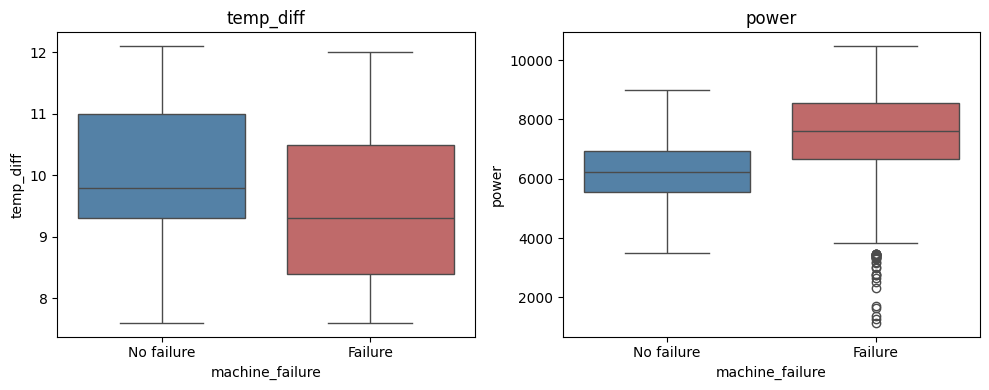

                 temp_diff   power
machine_failure                   
0                      9.8  6243.0
1                      9.3  7611.4


In [28]:
#I want to check whether the two new features really separate failures from normal records
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["temp_diff", "power"]):
    sns.boxplot(data=data, x="machine_failure", y=col, ax=ax, hue="machine_failure",
                palette=["steelblue", "indianred"], legend=False)
    ax.set_xticks([0, 1], ["No failure", "Failure"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(data.groupby("machine_failure")[["temp_diff", "power"]].median().round(1))

#my comments:
#-Temperature difference: median 9.8 K without failure and 9.3 K with failure, and the failure box reaches lower values (down to about 8.4 K at the first quartile).
#many failures happen when the difference is small: the machine cannot get rid of its heat (heat dissipation failure)

#-Power:median 6,243 W without failure and 7,611 W with failure.
#All normal records stay between about 3,500 and 9,000 W,
#while failures also appear outside this range: very high power (up to ~10,500 W) and a group of very low values (below ~3,500 W)
#This matches the definition of power failure (too little or too much power)

#both features are kept as inputs.
#I also keep the original sensors, because tool wear and torque are needed for the other failure modes (tool wear failure, overstrain failure)!!!

In [29]:
#I'll separate the input features (X) from the target I want to predict (y).
X = data.drop(columns=["machine_failure"])
y = data["machine_failure"]
print("X shape:", X.shape, "| y shape:", y.shape)
print(X.columns.tolist())

#label noise decision: in Section of Data Understanding I found 27 inconsistent rows (9 failures without a failure mode, 18 RNF rows without a failure)
#they are only 0.27% of the data and I cannot know which label is correct,
#so I keep them and use "Machine failure" as it is. I MENTIONED THIS ON THE REPORT AS LIMITATIONS!!!

X shape: (10000, 8) | y shape: (10000,)
['type', 'air_temp', 'process_temp', 'rotational_speed', 'torque', 'tool_wear', 'temp_diff', 'power']


In [30]:
from sklearn.model_selection import train_test_split

#the model must be evaluated on records it has never seen, to estimate how it would work on new machines. I keep 20% of the data for the test set as a rule
#- stratify=y keeps the same share of failures (3.39%) in both sets. Without it, with so few failures, the test set could get too many or too few of them by chance.
#- random_state=42 fixes the random split, so every run gives the same sets (reproducibility).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

#sizes of the two sets and the failure rate in each
print("Train:", X_train.shape, "| failure rate:", round(y_train.mean() * 100, 2), "%")
print("Test: ", X_test.shape, "| failure rate:", round(y_test.mean() * 100, 2), "%")
print("Failures in test set:", y_test.sum())

Train: (8000, 8) | failure rate: 3.39 %
Test:  (2000, 8) | failure rate: 3.4 %
Failures in test set: 68


## 4.1 Feature relevance

Before training, I check how much information each feature carries about the target.
Pearson correlation only measures linear relationships and rotational speed had almost zero correlation (-0.04) even though failures happen at both very low and very high speed.
Mutual information (MI) measures any kind of dependence, linear or not: MI = 0 means the feature tells nothing about the target, higher values mean more information.

                  mutual information  pearson
torque                        0.0471    0.190
power                         0.0467    0.176
rotational_speed              0.0349   -0.040
temp_diff                     0.0114   -0.111
tool_wear                     0.0100    0.099
air_temp                      0.0039    0.086
process_temp                  0.0027    0.041
type                          0.0012   -0.046


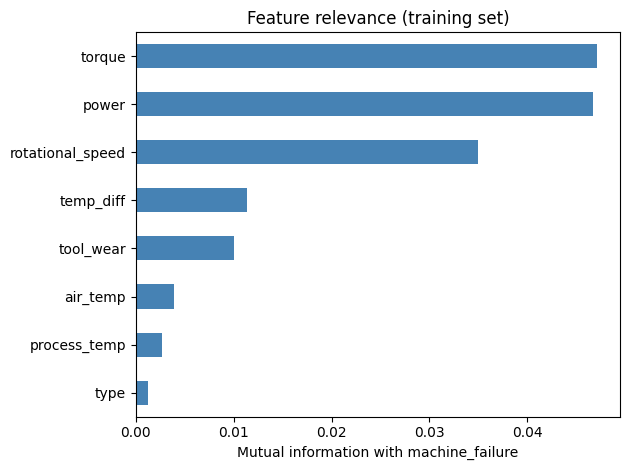

In [31]:
#I compute MI on the training set only, so the test set does not influence any decision that's why I put this code block here
#discrete_features tells the method that "type" is a category (0/1/2) and the others are continuous
#random_state=42 because the mutual information estimate uses random noise to break ties between equal values

#pearson correlation on the same training data, to compare the two measures side by side.

from sklearn.feature_selection import mutual_info_classif
mi_scores = mutual_info_classif(
    X_train, y_train,
    discrete_features=[col == "type" for col in X_train.columns],
    random_state=42)
mi = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

pearson = X_train.corrwith(y_train)

relevance = pd.DataFrame({"mutual information": mi.round(4), "pearson": pearson.round(3)}).loc[mi.index]
print(relevance)

ax = mi.plot(kind="barh", color="steelblue")
ax.invert_yaxis()
ax.set_xlabel("Mutual information with machine_failure")
ax.set_title("Feature relevance (training set)")
plt.tight_layout()
plt.show()


#- torque (0.047) and power (0.047) carry the most information, followed by rotational speed (0.035)
#- rotational speed has the third highest mutual information but a Pearson correlation of only -0.04.
#this is the proof that Pearson misses non-linear (U-shaped) relationships:
#failures happen at both low and high speed, so the linear correlation cancels out, while mutual information still sees the dependence

#power is as informative as torque, and temp_diff (0.011) is more informative than air temperature (0.004) or process temperature (0.003) alone
#tool wear has a low MI (0.010) because it matters only for one failure mode (tool wear failure, 46 cases), at high wear values.
#type has the lowest MI (0.001)

#I keep all 8 features. There are only 8, and none of them has MI = 0. Removing features would bring little gain and could lose the information that some failure modes need (for example tool wear for tool wear failures).
#MI gives me the insight of ranking features and their importance

In [32]:
from sklearn.preprocessing import StandardScaler

#the features have very different scales (power almost 6,000 W vs temperature difference almost 10 K).
#distance-based and gradient-based models (KNN, logistic regression, neural networks) need scaled features; tree-based models do not, so I keep both versions
#StandardScaler transforms each feature to mean 0 and standard deviation 1.
scaler = StandardScaler()

#the scaler learns the mean and std ONLY from the training set (fit), and then applies the same values to the test set (transform)
#if I fitted it on all the data, information from the test set would leak into training and the test score would be too optimistic.
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

#in the training set every feature now has mean almost 0 and std almost 1
#the test set is close to 0 and 1, but not exactly, because it was scaled with the training values
print(X_train_scaled.describe().loc[["mean", "std"]].round(2))
print(X_test_scaled.describe().loc[["mean", "std"]].round(2))

      type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
mean   0.0       0.0           0.0               0.0    -0.0       -0.0   
std    1.0       1.0           1.0               1.0     1.0        1.0   

      temp_diff  power  
mean       -0.0    0.0  
std         1.0    1.0  
      type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
mean  0.04     -0.00         -0.00             -0.02   -0.01       0.02   
std   1.02      1.01          1.01              0.95    0.97       1.00   

      temp_diff  power  
mean       0.00  -0.01  
std        1.01   0.98  


I want to summarize everthing in that point for report!!

### Summary of Data Preparation

| Step | What I did | Why |
| --- | --- | --- |
| Feature selection | dropped UDI, Product ID and the five failure modes | identifiers carry no information; failure modes would be data leakage |
| Encoding | Type: L = 0, M = 1, H = 2 | ordered categories, failure rate decreases with quality |
| Derived features | temperature difference, power | linked to heat dissipation and power failures, combine strongly correlated sensors |
| Label noise | kept the 27 inconsistent rows | 0.27% of the data, correct label unknown |
| Split | 80% train (8,000), 20% test (2,000), stratified, random_state = 42 | same failure rate in both sets, reproducible |
| Scaling | StandardScaler fitted on the training set only | needed for KNN / logistic regression / neural networks; no leakage |

Final input: **8 features** (type, air_temp, process_temp, rotational_speed, torque, tool_wear, temp_diff, power). I use `X_train` / `X_test` for tree-based models and `X_train_scaled` / `X_test_scaled` for scale-sensitive models.

**Class imbalance:** I don't oversample the data here. In Modeling I will first try `class_weight="balanced"`, which tells the model that a missed failure costs more and compare it with the default.

# 5. Modeling

I am planning to train different models one by one, from the simplest to the more complex because I want to see differences. After each one I explain what I learned and why I try the next model.

**Evaluation protocol (the same for every model):**

- Every model is trained only on the training set (8,000 records, 271 failures).
- All choices (hyperparameters, class weights) are made with **5-fold stratified cross-validation on the training set**.
`The test set (2,000 records, 68 failures) is used only once per model, to report the final result. If I chose the hyperparameters by looking at the test set, the test score would become too optimistic`

- Metrics:
  * **recall** (main metric)
  * **precision**
  * **F2-score** (used to compare and select models)
  * **PR-AUC** (quality of the predicted probabilities, independent of the threshold)
  * **confusion matrix**
  * **accuracy** only as a reference
- I compare training and test results to detect **overfitting**

**Note on the size of the test set:** with 68 failures in the test set, one failure more or less changes recall by about 1.5 percentage points. Small differences between models on the test set can therefore be due to chance, which is another reason to select models with cross-validation.

In [33]:
#same 5 folds for every model, so the cross-validation results are comparable.
#StratifiedKFold keeps the failure rate (3.39%) in every fold; shuffle + random_state make it reproducible.

#f2_scorrer is my selection metric. sklearn has no ready "f2" name, so I build a scorer
#from fbeta_score with beta=2 (recall counts more than precision)
#one function that computes all my metrics, so every model is evaluated in exactly the same way.


from sklearn.metrics import (accuracy_score, precision_score, recall_score, fbeta_score, average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f2_scorer = make_scorer(fbeta_score, beta=2)

def evaluate(model, X, y):
    y_pred = model.predict(X)                  # predicted class (0/1) with the default threshold 0.5
    y_proba = model.predict_proba(X)[:, 1]     # predicted probability of failure
    return {
        "accuracy": accuracy_score(y, y_pred),
        "recall": recall_score(y, y_pred, zero_division=0),
        "precision": precision_score(y, y_pred, zero_division=0),
        "F2": fbeta_score(y, y_pred, beta=2, zero_division=0),
        "PR-AUC": average_precision_score(y, y_proba),
    }

#confusion matrix plot, to see the errors as numbers of machines and not only as percentages.
def plot_confusion(model, X, y, title):
    cm = confusion_matrix(y, model.predict(X))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No failure", "Failure"], yticklabels=["No failure", "Failure"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()

#I collect the test results of every model here, to build the final comparison table.
results = {}

## 4.1 Baseline: always predict "no failure"

Before any real model, I need a reference point. The simplest possible "model" ignores the sensors and always predicts the majority class. Every real model must clearly beat it

accuracy     0.966
recall       0.000
precision    0.000
F2           0.000
PR-AUC       0.034
dtype: float64


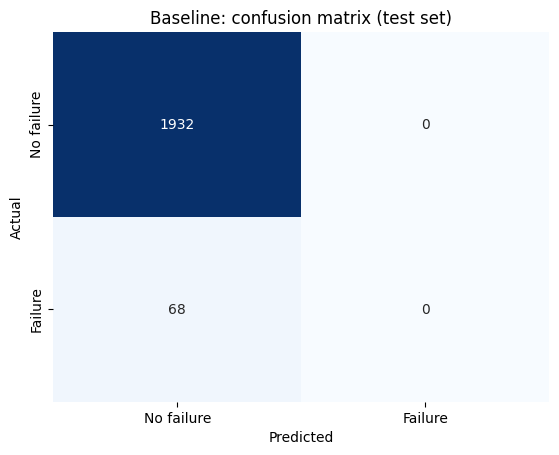

In [34]:
#strategy="most_frequent" always predicts the most common class in the training set (0 = no failure)

from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

results["Baseline (always 0)"] = evaluate(baseline, X_test, y_test)
print(pd.Series(results["Baseline (always 0)"]).round(3))
plot_confusion(baseline, X_test, y_test, "Baseline: confusion matrix (test set)")


#so the accuracy is 96.6%, but recall, precision and F2 are 0
#baseline misses all 68 failures in the test set.
#PR-AUC is 0.034, which is just the failure rate (a random guess)

#this is the numerical proof of what I wrote in Section 1: on this imbalanced dataset a useless model gets 96.6% accuracy.
#from now on accuracy is only shown for reference, and models are compared with recall, F2 and PR-AUC. I'll also mentioned this on the report because this is important.

## 4.2 Decision Tree

The decision tree is the first classifier of the course (Hunt's algorithm; scikit-learn implements CART with Gini impurity and binary splits). I start with it because:

- it can model the non-linear patterns I found in Section 2 (failures at both very low and very high speed or power) by cutting a feature at several thresholds;
- it does not need scaling, so I use the unscaled `X_train` / `X_test`;
- its rules can be read, so I can check whether they make physical sense

First I train a tree with the default settings, which grows until every leaf is pure.

In [36]:
#default settings = no depth limit, so the tree keeps splitting until every leaf contains one class
#random_state=42 similar to my previous decision of why we said 42

from sklearn.tree import DecisionTreeClassifier
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_train, y_train)

print("Depth:", dt_full.get_depth(), "| leaves:", dt_full.get_n_leaves())

#I also want to do comparing training and test results shows whether the tree memorised the training data.
comparison = pd.DataFrame({"train": evaluate(dt_full, X_train, y_train),
                           "test": evaluate(dt_full, X_test, y_test)}).round(3)
print(comparison)

#the unlimited tree has depth 17 and 108 leaves.
#on the training set every metric is 1.0 (perfect), but on the test set recall is 0.735, precision 0.758 and F2 0.740.

#perfect training score with a much lower test score is the classic sign of OVERFITTING!!!!
#the tree learned the training records by heart, including noise, instead of general rules.
#solution from the course is to limit the growth of the tree (PRUNNING!!!)
#this unlimited tree already finds about 74% of the failures, far better than the baseline, which confirms that the sensors contain a strong signal

Depth: 17 | leaves: 108
           train   test
accuracy     1.0  0.983
recall       1.0  0.735
precision    1.0  0.758
F2           1.0  0.740
PR-AUC       1.0  0.566


In [37]:
#hyperparameter tuning with grid search and 5-fold cross-validation on the training set only

#- max_depth: how deep the tree can grow (None = no limit). Smaller trees overfit less.
#- min_samples_leaf: minimum number of records in a leaf. Larger values avoid leaves built on 1-2 records.
#- class_weight: None treats both classes equally; "balanced" gives failures a weight about 28 times higher (9,661 / 339),
#missed failure costs more, like the cost matrix in the course!!!
# scoring=f2_scorer: the best combination is the one with the highest mean F2 over the 5 folds.

param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "class_weight": [None, "balanced"],
}
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                         scoring=f2_scorer, cv=cv)
dt_search.fit(X_train, y_train)

print("Combinations tested:", len(dt_search.cv_results_["params"]), "x 5 folds")
print("Best parameters:", dt_search.best_params_)
print("Best mean F2 in cross-validation:", round(dt_search.best_score_, 3))

#the best result for each class_weight option, to see the effect of weighting the classes.
cv_table = pd.DataFrame(dt_search.cv_results_)
cv_table["class_weight"] = cv_table["param_class_weight"].astype(str)
print(cv_table.groupby("class_weight")["mean_test_score"].max().round(3))


#56 combinations were tested.
#best one has max_depth = 10, min_samples_leaf = 1 and no class weight, with a mean cross-validated F2 of 0.773 (the unlimited tree scores 0.758 with the same procedure)
#best "balanced" tree reaches 0.753.

#limiting the depth to 10 improves the cross-validated F2, so pruning helps!!
#below I check both the selected tree and the best balanced tree on the test set, because the class weight changes the type of errors the model makes

Combinations tested: 56 x 5 folds
Best parameters: {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 1}
Best mean F2 in cross-validation: 0.773
class_weight
None        0.773
balanced    0.753
Name: mean_test_score, dtype: float64


Depth: 10 | leaves: 65
           train   test
accuracy   0.996  0.985
recall     0.908  0.706
precision  0.984  0.828
F2         0.922  0.727
PR-AUC     0.965  0.649


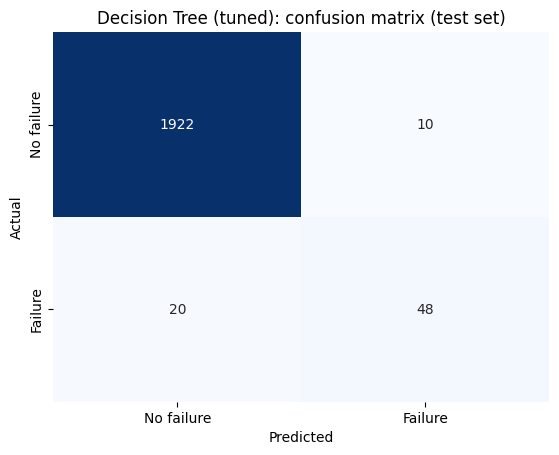

In [39]:
#best tree chosen by cross-validation (GridSearchCV retrains it on the whole training set):
dt_best = dt_search.best_estimator_
print("Depth:", dt_best.get_depth(), "| leaves:", dt_best.get_n_leaves())
print(pd.DataFrame({"train": evaluate(dt_best, X_train, y_train),
                    "test": evaluate(dt_best, X_test, y_test)}).round(3))
plot_confusion(dt_best, X_test, y_test, "Decision Tree (tuned): confusion matrix (test set)")

Best balanced parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 5}
           train   test
accuracy   0.984  0.974
recall     1.000  0.809
precision  0.683  0.579
F2         0.915  0.749
PR-AUC     0.970  0.765


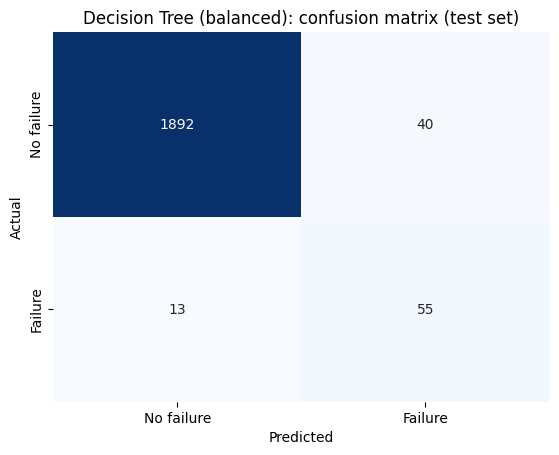

In [41]:
#best tree with class_weight="balanced", to see how weighting the failures changes the errors:
best_balanced = (cv_table[cv_table["class_weight"] == "balanced"]
                 .sort_values("mean_test_score", ascending=False).iloc[0]["params"])
print("Best balanced parameters:", best_balanced)
dt_balanced = DecisionTreeClassifier(random_state=42, **best_balanced).fit(X_train, y_train)
print(pd.DataFrame({"train": evaluate(dt_balanced, X_train, y_train),
                    "test": evaluate(dt_balanced, X_test, y_test)}).round(3))
plot_confusion(dt_balanced, X_test, y_test, "Decision Tree (balanced): confusion matrix (test set)")

In [43]:
results["Decision Tree (default)"] = evaluate(dt_full, X_test, y_test)
results["Decision Tree (tuned)"] = evaluate(dt_best, X_test, y_test)
results["Decision Tree (balanced)"] = evaluate(dt_balanced, X_test, y_test)

#I understand all of that:
#tuned tree has a smaller gap between training (F2 0.92) and test than the unlimited tree, so it overfits less.
#on the test set its F2 (0.727) is slightly lower than the unlimited tree (0.740),
#but the difference is one failure: with only 68 test failures this is within chance, and the cross-validation (which averages 5 folds) prefers the tuned tree

#balanced tree catches 8 more failures (56 instead of 48) at the cost of 31 more false alarms (41 instead of 10).
#this is exactly the recall-precision trade-off like giving failures a higher weight moves the model towards fewer missed failures and more unnecessary inspections

#I understand that which tree is better depends on the real cost ratio between a missed failure and a false alarm.
#if a missed failure costs much more than an inspection (my assumption in Section 1), the balanced tree is attractive even with more false alarms


#I will come back to this trade-off with threshold selection for the final model; class weights are one way to move it, changing the decision threshold is another!!!!

|--- power <= 9001.23
|   |--- power <= 3496.14
|   |   |--- class: 1
|   |--- power >  3496.14
|   |   |--- rotational_speed <= 1380.50
|   |   |   |--- temp_diff <= 8.55
|   |   |   |   |--- class: 1
|   |   |   |--- temp_diff >  8.55
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- rotational_speed >  1380.50
|   |   |   |--- tool_wear <= 204.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- tool_wear >  204.50
|   |   |   |   |--- truncated branch of depth 7
|--- power >  9001.23
|   |--- class: 1



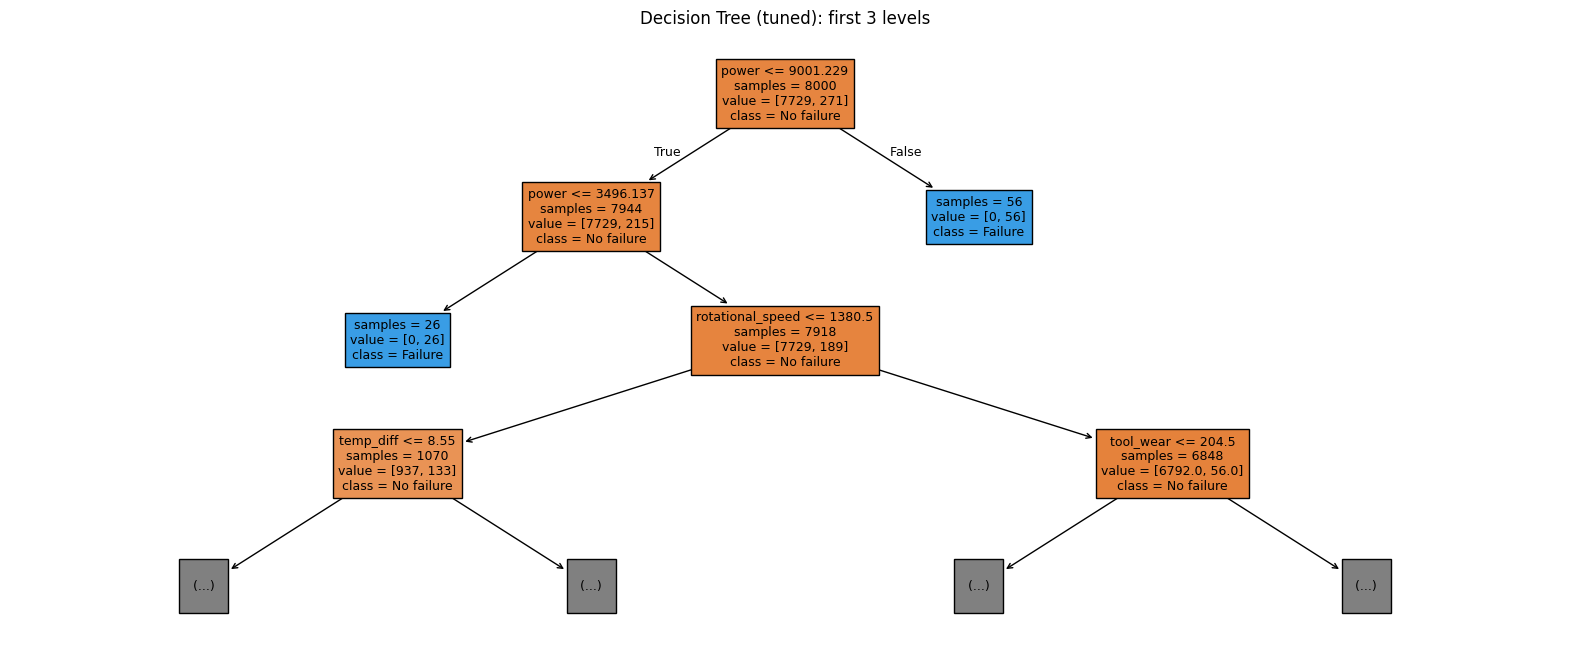

power               0.386
temp_diff           0.293
tool_wear           0.133
rotational_speed    0.077
torque              0.050
type                0.042
process_temp        0.014
air_temp            0.006
dtype: float64


In [44]:
#main advantage of a tree is that its rules can be read. I print the first levels of the tuned tree to check whether they make physical sense.

from sklearn.tree import plot_tree, export_text
print(export_text(dt_best, feature_names=list(X_train.columns), max_depth=3))

plt.figure(figsize=(20, 8))
plot_tree(dt_best, max_depth=3, feature_names=X_train.columns, class_names=["No failure", "Failure"],
          filled=True, impurity=False, proportion=False, fontsize=9)
plt.title("Decision Tree (tuned): first 3 levels")
plt.show()

#feature importance: how much each feature reduces the Gini impurity over all the splits
importance = pd.Series(dt_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importance.round(3))

##I'LL USE THIS GRAPH ON REPORT!!!!

------- what I understand from the graph:-------

the first splits of the tree are almost exactly the failure definitions of the dataset, found by the tree **without ever seeing the failure-mode columns**:

- **power <= 3,496 W -> failure** and **power > 9,001 W -> failure**: this is power failure (PWF), which happens when the power is below 3,500 W or above 9,000 W. These two leaves are completely pure: they contain 26 + 56 = 82 training records, all failures (30% of the 271 training failures) and no normal record.

- **rotational_speed <= 1,380 rpm and temp_diff <= 8.55 K -> failure**: this is heat dissipation failure (HDF), which happens when the temperature difference is below 8.6 K and the speed is below 1,380 rpm.

- **tool_wear > 204.5 min** opens the branch of tool wear failure (TWF), which happens between 200 and 240 minutes.

Feature importance: **power 0.386, temp_diff 0.293, tool_wear 0.133**, rotational_speed 0.077, torque 0.050, type 0.042, the two raw temperatures below 0.02.

------- my internal comments based on these data that I saw:-------

- two derived features I created in Data Preparation (power and temp_diff) are the two most important features of the model: the feature engineering was the most useful step so far.

- Because the tree recovers the physical failure rules, I can trust that it learned real patterns and not noise. This also explains why the tree works well here: the failures are defined by thresholds, and thresholds are exactly what a tree learns.

- The remaining errors are mostly failures that no threshold explains: random failures (RNF) and the 9 failures without a failure mode found in Section 2.

In [45]:
#I'll run a comparison table, updated after every model to see differences of the models:
pd.DataFrame(results).T.round(3)

,accuracy,recall,precision,F2,PR-AUC
Baseline (always 0),0.966,0.000,0.000,0.000,0.034
Decision Tree (default),0.983,0.735,0.758,0.740,0.566
Decision Tree (tuned),0.985,0.706,0.828,0.727,0.649
Decision Tree (balanced),0.974,0.809,0.579,0.749,0.765
